# Tree Species Classification Using Deep Learning

**Course:** Neural Networks — 2026

**Group members:**

Timofey Krylov (timofey.krylov@student.hamk.fi)

Tomi Kitola (tomi.kitola@student.hamk.fi)

Jaakko Ruhanen (jaakko.ruhanen@student.hamk.fi)



## Project Overview

This project focuses on classifying urban tree species using pretrained convolutional neural networks (CNNs).

Two models, ResNet18 and ResNet50, are trained and compared using the same dataset.

The project covers image preprocessing, data augmentation, transfer learning, model evaluation, error analysis, and model improvement.

**Dataset:** [Tree Dataset of Urban Street](https://www.kaggle.com/datasets/erickendric/tree-dataset-of-urban-street-classification-tree)

### Requirements & Installation

Before running the notebook, install the required Python libraries in your environment.

```bash
python -m pip install numpy torch torchvision Pillow matplotlib seaborn pandas scikit-learn kagglehub ipykernel
```

The libraries only need to be installed once per environment.

Note: GPU acceleration may require a separate PyTorch installation.

## 0. Environment Setup

In [8]:
#  imports
import os, random, time, copy

import numpy as np
import torch, torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms as T
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, classification_report)


plt.rcParams["figure.dpi"] = 90

# Reproducibility
SEED = 42

def setup(device_preference="cuda", seed=42):
    use_cuda = torch.cuda.is_available() and device_preference == "cuda"
    device = torch.device("cuda" if use_cuda else "cpu")
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if use_cuda:
        torch.cuda.manual_seed_all(seed)
        # For speed (slightly less deterministic); set to False + deterministic=True if you need strict determinism
        torch.backends.cudnn.benchmark = True
    return device

# Device and DataLoader settings
device = setup(seed=SEED)
NUM_WORKERS = 0 if os.name == "nt" else 2

plt.rcParams["figure.dpi"] = 90

print("Device:", device)


Device: cuda


In [9]:
# Save trained models separately from the submission ZIP.
# Google Colab: Google Drive | Local environment: models/
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/nncv_tree_models"
except ImportError:
    SAVE_DIR = "models"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Models will be saved to:", SAVE_DIR)

Models will be saved to: models


## 1. Dataset: Tree Dataset of Urban Street

The dataset contains images of urban street trees collected across 10 cities and different seasons.

Images are organized by species, with folder names used as class labels.

The dataset is explored and divided into stratified training (70%), validation (15%), and test (15%) sets.

In [10]:
# Download the dataset from Kaggle

import kagglehub

path = kagglehub.dataset_download("erickendric/tree-dataset-of-urban-street-classification-tree")
print("Dataset folder:", path)

Dataset folder: C:\Users\valen\.cache\kagglehub\datasets\erickendric\tree-dataset-of-urban-street-classification-tree\versions\1


In [11]:
# Inspect the dataset folder structure
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 2:
        print("    " * depth + os.path.basename(root) + f"/  ({len(files)} files)")

1/  (0 files)
    tree/  (0 files)
        test/  (0 files)
        train/  (0 files)
        val/  (0 files)


In [12]:
# Collect image paths and assign species labels using folder names.
# Use unique (species, filename) keys to avoid duplicate entries.
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

images = {}
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(IMG_EXT):
            images[(os.path.basename(root), f)] = os.path.join(root, f)

all_species = [k[0] for k in images]
all_paths   = list(images.values())
class_names = sorted(set(all_species))
num_classes = len(class_names)

print("Images:", len(all_paths), "| Classes:", num_classes)
print(class_names)

Images: 4804 | Classes: 23
['Acer palmatum', 'Cedrus deodara', 'Celtis sinensis', 'Cinnamomum camphora (Linn) Presl', 'Elaeocarpus decipiens', 'Flowering cherry', 'Ginkgo biloba', 'Koelreuteria paniculata', 'Lagerstroemia indica', 'Liquidambar formosana', 'Liriodendron chinense', 'Magnolia grandiflora L', 'Magnolia liliflora Desr', 'Michelia chapensis', 'Osmanthus fragrans', 'Photinia serratifolia', 'Platanus', 'Prunus cerasifera f. atropurpurea', 'Salix babylonica', 'Sapindus saponaria', 'Styphnolobium japonicum', 'Triadica sebifera', 'Zelkova serrata']


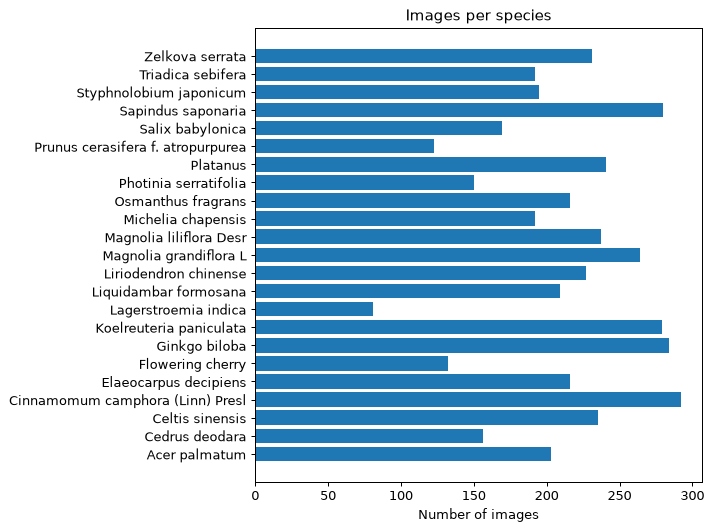

Smallest class: Lagerstroemia indica 81 | Biggest class: Cinnamomum camphora (Linn) Presl 292


In [13]:
# Visualize the number of images per species
counts = pd.Series(all_species).value_counts().sort_index()

plt.figure(figsize=(8, 6))
plt.barh(counts.index, counts.values)
plt.xlabel("Number of images"); plt.title("Images per species")
plt.tight_layout(); plt.show()

print("Smallest class:", counts.idxmin(), counts.min(), "| Biggest class:", counts.idxmax(), counts.max())

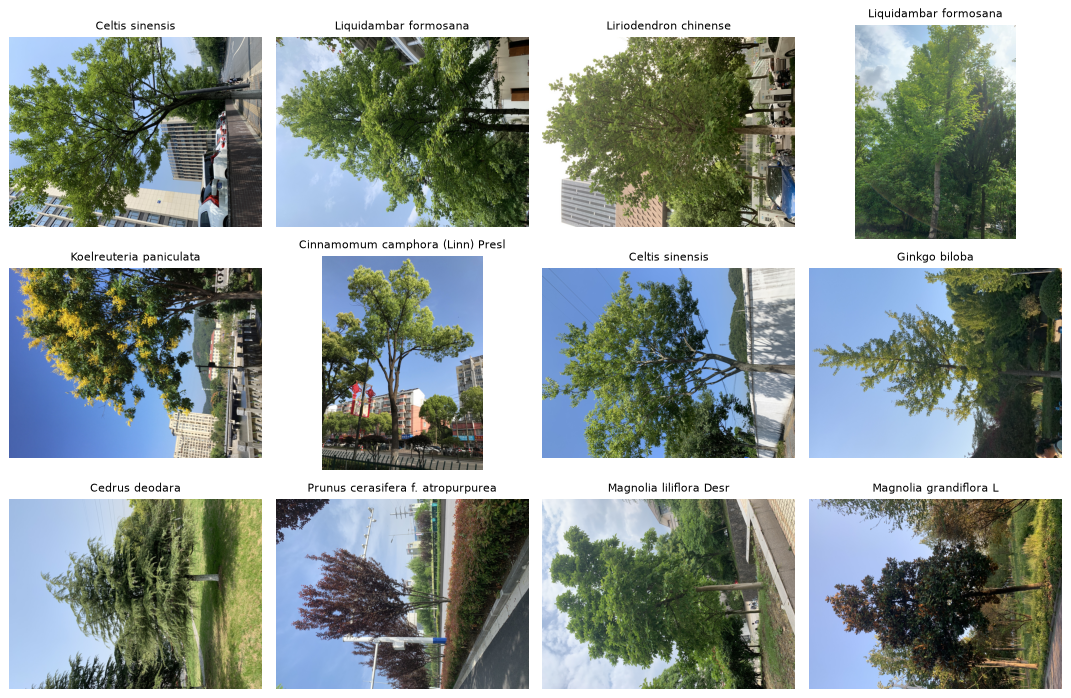

In [14]:
# Display random samples from the dataset
fig, axs = plt.subplots(3, 4, figsize=(12, 8))
for ax, i in zip(axs.ravel(), random.sample(range(len(all_paths)), 12)):
    ax.imshow(ImageOps.exif_transpose(Image.open(all_paths[i])))
    ax.set_title(all_species[i], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Pixels & Image Tensors

**Key ideas**
- Tree images use **RGB** with 3 color channels
- PIL/NumPy format: `(H, W, 3)`
- PyTorch tensor format: `(3, H, W)`
- Image size affects memory usage and training speed

In [15]:
# Inspect one tree image
img = ImageOps.exif_transpose(Image.open(all_paths[0])).convert("RGB")
x = T.ToTensor()(img)

print("PIL size (W, H):", img.size)
print("Tensor shape:", x.shape)
print("Data type:", x.dtype)
print("Min/Max:", float(x.min()), float(x.max()))

# Compare input sizes
print("Flattened RGB 224x224:", 3 * 224 * 224)
print("Flattened MNIST 28x28:", 28 * 28)

# Check original image sizes
sizes = [Image.open(p).size for p in random.sample(all_paths, 50)]

print("Examples:", sizes[:8])
print("Width range:", min(s[0] for s in sizes), "-", max(s[0] for s in sizes))
print("Height range:", min(s[1] for s in sizes), "-", max(s[1] for s in sizes))

PIL size (W, H): (1600, 1200)
Tensor shape: torch.Size([3, 1200, 1600])
Data type: torch.float32
Min/Max: 0.0 1.0
Flattened RGB 224x224: 150528
Flattened MNIST 28x28: 784
Examples: [(1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200), (1600, 1200)]
Width range: 1200 - 1600
Height range: 1200 - 1600


## 3. What is Image Classification?

**Key ideas**
- Input: RGB image tensor `[3, 224, 224]`
- Output: one of **23 tree species**
- Model predicts **23 logits**, one for each class
- Loss function: **CrossEntropyLoss**
- Evaluation: **Accuracy, Precision, Recall, F1-score**
- Additional evaluation: **Confusion Matrix and Top-N Accuracy**

## 4. Image Preprocessing & Dataset Split

**Key ideas**
- Resize images to 256 pixels while keeping aspect ratio
- Convert images to RGB
- Skip broken images
- Split dataset into 70% Train, 15% Validation and 15% Test
- Keep class proportions balanced across all splits

In [16]:
# Resize and save images
SMALL_DIR = "data_small"
shrink = T.Resize(256)

paths, species = [], []
start = time.time()

for i, (p, sp) in enumerate(zip(all_paths, all_species)):
    out_dir = os.path.join(SMALL_DIR, sp)
    os.makedirs(out_dir, exist_ok=True)

    out_path = os.path.join(out_dir, f"{i}.jpg")

    if not os.path.exists(out_path):
        try:
            im = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
            shrink(im).save(out_path, quality=95)
        except Exception as e:
            print("Skipped broken image:", p, e)
            continue

    paths.append(out_path)
    species.append(sp)

print(f"{len(paths)} images ready in {time.time() - start:.0f} s")


# Train / Validation / Test split
labels = [class_names.index(s) for s in species]

train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=0.30,
    stratify=labels, random_state=SEED
)

val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50,
    stratify=temp_y, random_state=SEED
)

print("Train:", len(train_p))
print("Validation:", len(val_p))
print("Test:", len(test_p))

4804 images ready in 0 s
Train: 3362
Validation: 721
Test: 721


## 5. Transforms & Augmentation
**Why transforms?**
- Put images into the right format/range (`ToTensor`).
- Standardize scale per channel (`Normalize`) — here with **ImageNet mean/std**, because the pretrained
  ResNet weights were trained with those values (so we don't need `compute_mean_std` like with MNIST).
- Ensure common sizes for batching (`Resize` / `CenterCrop` / `RandomResizedCrop`).
- Increase diversity with randomness (augmentations) → less overfitting.

### Visualization Resize and Augmentation

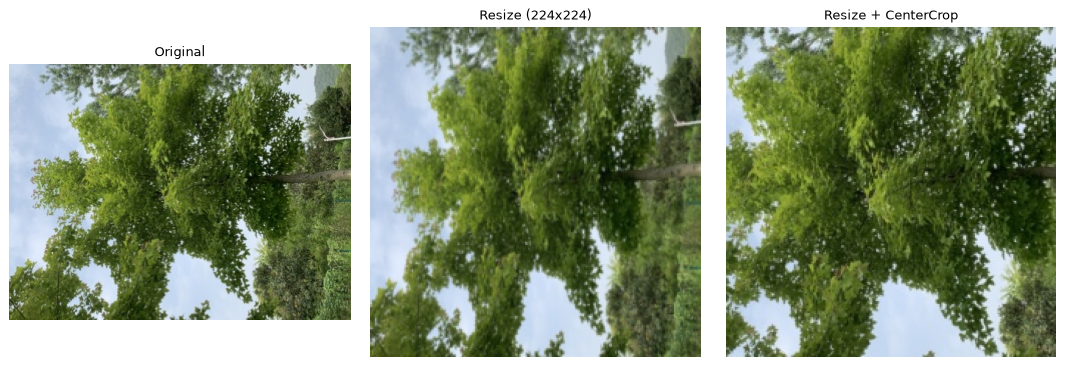

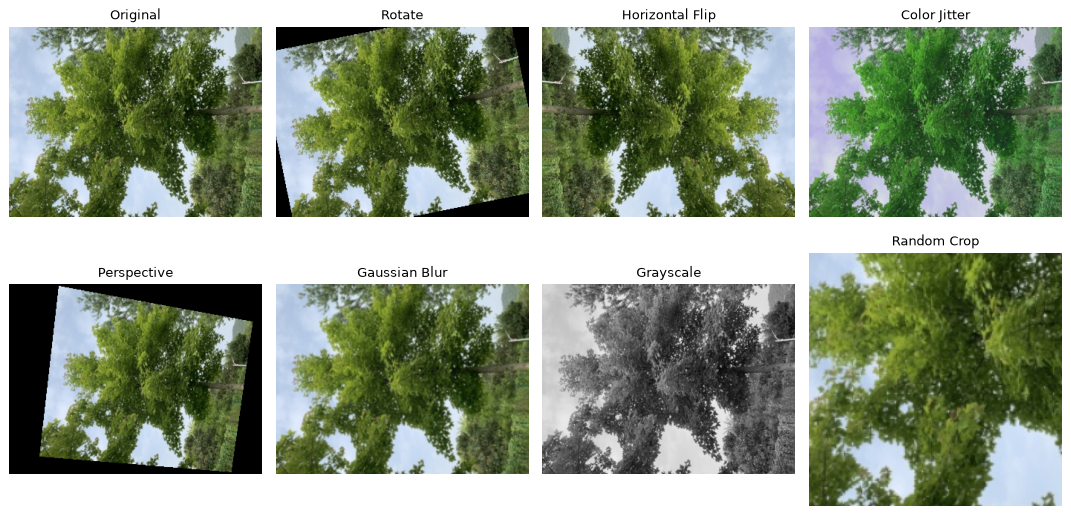

In [17]:
# Load sample image
img = Image.open(train_p[0]).convert("RGB")

# Compare resizing methods
variants = [
    ("Original", img),
    ("Resize (224x224)", T.Resize((224, 224))(img)),
    ("Resize + CenterCrop", T.Compose([
        T.Resize(256), T.CenterCrop(224)
    ])(img))
]

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, im) in zip(axs, variants):
    ax.imshow(im)
    ax.set_title(name, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Compare data augmentations
augs = [
    ("Rotate", T.RandomRotation(15)),
    ("Horizontal Flip", T.RandomHorizontalFlip(p=1.0)),
    ("Color Jitter", T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1)),
    ("Perspective", T.RandomPerspective(distortion_scale=0.4, p=1.0)),
    ("Gaussian Blur", T.GaussianBlur(kernel_size=9, sigma=(0.1, 2.0))),
    ("Grayscale", T.RandomGrayscale(p=1.0)),
    ("Random Crop", T.RandomResizedCrop(224))
]

fig, axs = plt.subplots(2, 4, figsize=(12, 6))
axs = axs.ravel()

axs[0].imshow(img)
axs[0].set_title("Original", fontsize=10)
axs[0].axis("off")

for i, (name, aug) in enumerate(augs, start=1):
    axs[i].imshow(aug(img))
    axs[i].set_title(name, fontsize=10)
    axs[i].axis("off")

plt.tight_layout()
plt.show()

### Transform Recipes — Round 1

- Training: RandomResizedCrop and RandomHorizontalFlip
- Validation and Test: Resize and CenterCrop
- All images are converted to tensors and normalized using ImageNet values
- Random augmentations are applied only to training images

In [18]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tfms = T.Compose([
    T.RandomResizedCrop(224),          # random part of the image, resized to 224x224
    T.RandomHorizontalFlip(),          # trees look the same mirrored
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_tfms = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_tfms, val_tfms

(Compose(
     RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
     RandomHorizontalFlip(p=0.5)
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ),
 Compose(
     Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
     CenterCrop(size=(224, 224))
     ToTensor()
     Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
 ))

### Dataset & DataLoaders

In [19]:
class TreeDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]


pin = device.type == "cuda"

def make_loaders(train_transform, batch_size=32):
    return {
        "train": DataLoader(
            TreeDataset(train_p, train_y, train_transform),
            batch_size=batch_size,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=pin
        ),
        "val": DataLoader(
            TreeDataset(val_p, val_y, val_tfms),
            batch_size=64,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=pin
        ),
        "test": DataLoader(
            TreeDataset(test_p, test_y, val_tfms),
            batch_size=64,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=pin
        )
    }


loaders = make_loaders(train_tfms)

xb, yb = next(iter(loaders["train"]))
print(xb.shape, yb.shape)

torch.Size([32, 3, 224, 224]) torch.Size([32])


## 6. Modeling: Pretrained ResNets

**Models**
| | ResNet18 | ResNet50 |
|---|---|---|
| Layers | 18 | 50 |
| Parameters | ~11.7M | ~25.6M |
| Features | 512 | 2048 |
| ImageNet Accuracy | 69.8% | 76.1% |

**Transfer Learning**
- Both models use pretrained ImageNet weights
- The final layer is replaced to predict **23 tree species**
- All layers are trained using a small learning rate
- We compare accuracy and training performance

In [20]:
def make_model(name, num_classes=num_classes):
    if name == "resnet18":
        model = models.resnet18(weights="IMAGENET1K_V1")
    elif name == "resnet50":
        model = models.resnet50(weights="IMAGENET1K_V1")
    else:
        raise ValueError(name)

    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)


def count_params(model):
    return sum(p.numel() for p in model.parameters())


for name in ["resnet18", "resnet50"]:
    m = make_model(name)
    print(f"{name}: {count_params(m)/1e6:.1f} M parameters | last layer: {m.fc}")

del m

resnet18: 11.2 M parameters | last layer: Linear(in_features=512, out_features=23, bias=True)
resnet50: 23.6 M parameters | last layer: Linear(in_features=2048, out_features=23, bias=True)


### Training & Evaluation Helpers

**Key ideas**
- Train models and track loss and accuracy
- Use `CrossEntropyLoss`, Adam and StepLR
- Save the best model based on validation accuracy
- Evaluate models using Accuracy, Precision, Recall and F1
- Visualize learning curves, confusion matrices and prediction errors
- Calculate Top-N Accuracy

In [21]:
# ---------------- Training helpers ----------------

def denorm(x, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    # Undo ImageNet normalization for display; x has shape [H, W, 3]
    return (x * torch.tensor(std) + torch.tensor(mean)).clamp(0, 1)


def show_batch(loader, n=16, nrow=8):
    # Show a batch of sample images from a DataLoader (after transforms/augmentation)
    xb, yb = next(iter(loader))
    grid = torchvision.utils.make_grid(xb[:n], nrow=nrow, padding=2)
    plt.figure(figsize=(14, 4))
    plt.imshow(denorm(grid.permute(1, 2, 0)))
    plt.axis("off"); plt.title("Sample training batch"); plt.show()
    print("Labels:", [class_names[i] for i in yb[:n]])


def evaluate_loader(model, loader, loss_fn, device):
    # Average loss and accuracy over a loader
    model.eval()
    total, correct, running = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            running += loss_fn(out, yb).item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return running / total, correct / total


def train_epochs(model, train_loader, val_loader, epochs=15, lr=1e-4, wd=1e-4,
                 step_size=7, label_smoothing=0.0, device="cpu"):
    # Train a model for multiple epochs, with validation at each epoch.
    # Returns the model with the BEST validation weights + history dictionary.
    ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sched = lr_scheduler.StepLR(opt, step_size=step_size, gamma=0.1)   # from the transfer learning tutorial
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())
    start = time.time()

    for ep in range(1, epochs + 1):
        model.train()
        running, correct = 0.0, 0

        # Training loop
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = ce(out, yb)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

            running += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
        sched.step()

        train_loss = running / len(train_loader.dataset)
        train_acc = correct / len(train_loader.dataset)
        val_loss, val_acc = evaluate_loader(model, val_loader, ce, device)

        hist["train_loss"].append(train_loss); hist["train_acc"].append(train_acc)
        hist["val_loss"].append(val_loss);     hist["val_acc"].append(val_acc)

        mark = ""
        if val_acc > best_acc:   # keep the best epoch
            best_acc, best_wts, mark = val_acc, copy.deepcopy(model.state_dict()), "  *best*"
        print(f"Epoch {ep:2d} | train={train_loss:.4f} acc={train_acc:.4f} | "
              f"val={val_loss:.4f} acc={val_acc:.4f}{mark}")

    print(f"Training time: {(time.time() - start) / 60:.1f} min | best val acc: {best_acc:.4f}")
    model.load_state_dict(best_wts)
    return model, hist


def plot_curves(hist, title=""):
    # Loss and accuracy curves for train and validation
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    ax1.plot(epochs, hist["train_loss"], label="train_loss")
    ax1.plot(epochs, hist["val_loss"], label="val_loss")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title(title + " loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(epochs, hist["train_acc"], label="train_acc")
    ax2.plot(epochs, hist["val_acc"], label="val_acc")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1); ax2.set_title(title + " accuracy")
    ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

In [22]:
# ---------------- Evaluation helpers ----------------

def get_predictions(model, loader, device="cpu"):
    # True labels, predicted labels and softmax probabilities (probabilities are needed for n-best)
    model.eval(); ys, probs = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            probs.append(torch.softmax(out, dim=1).cpu())
            ys.append(yb)
    probs = torch.cat(probs).numpy()
    y_true = torch.cat(ys).numpy()
    return y_true, probs.argmax(1), probs


results = {}   # test results of every model, used for the comparisons

def test_model(model, name, loader):
    # Accuracy + macro precision / recall / F1 on the test set, stored in `results`
    y_true, y_pred, probs = get_predictions(model, loader, device)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    results[name] = dict(y_true=y_true, y_pred=y_pred, probs=probs,
                         accuracy=acc, precision=prec, recall=rec, f1=f1)
    print(f"{name:12s} | accuracy {acc:.4f} | precision {prec:.4f} | recall {rec:.4f} | F1 {f1:.4f}")


def show_confusion_matrices(name, labels=class_names, min_pct_annot=0.05, hide_diag_on_norm=False):
    # show_confusion_matrices is made bigger for 23 classes
    y_true, y_pred = results[name]["y_true"], results[name]["y_pred"]
    n = len(labels)
    cm_raw  = confusion_matrix(y_true, y_pred, labels=range(n))
    cm_norm = confusion_matrix(y_true, y_pred, labels=range(n), normalize="true")

    fig, axes = plt.subplots(1, 2, figsize=(24, 10))

    ann_raw = np.where(cm_raw == 0, "", cm_raw.astype(int))  # hide zeros
    sns.heatmap(cm_raw, ax=axes[0], annot=ann_raw, fmt="", cmap="Blues", cbar=False, square=True,
                linewidths=.5, linecolor="white", annot_kws={"size": 7},
                xticklabels=labels, yticklabels=labels)
    axes[0].set_title(f"{name} — confusion matrix (counts)")

    ann_norm = np.where(cm_norm >= min_pct_annot, np.round(cm_norm * 100).astype(int).astype(str), "")
    mask = np.eye(n, dtype=bool) if hide_diag_on_norm else None
    sns.heatmap(cm_norm, ax=axes[1], annot=ann_norm, fmt="", cmap="Blues", vmin=0, vmax=1, square=True,
                linewidths=.5, linecolor="white", mask=mask, annot_kws={"size": 7},
                xticklabels=labels, yticklabels=labels)
    axes[1].set_title(f"{name} — normalized % (≥{int(min_pct_annot*100)}% annotated)")

    for ax in axes:
        ax.set_xlabel("Pred"); ax.set_ylabel("True")
        ax.tick_params(axis="x", labelrotation=90, labelsize=8)
        ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    plt.tight_layout(); plt.show()


def most_confused(name, top=10):
    # The most common (true -> predicted) mistakes
    cm = confusion_matrix(results[name]["y_true"], results[name]["y_pred"], labels=range(num_classes))
    np.fill_diagonal(cm, 0)
    pairs = [(cm[i, j], class_names[i], class_names[j])
             for i in range(num_classes) for j in range(num_classes) if cm[i, j] > 0]
    pairs.sort(reverse=True)
    print(f"--- {name}: most common errors (true → predicted) ---")
    for c, t, p in pairs[:top]:
        print(f"{c:3d}   {t}  →  {p}")


def show_misclassified(name, k=20, nrow=5):
    # Grid of k random wrong test predictions (original resized photo, true / predicted + confidence)
    r = results[name]
    wrong = np.where(r["y_true"] != r["y_pred"])[0]
    print(f"{name}: {len(wrong)} wrong out of {len(r['y_true'])} test images")
    pick = random.sample(list(wrong), min(k, len(wrong)))
    fig, axs = plt.subplots((len(pick) + nrow - 1) // nrow, nrow, figsize=(16, 3.6 * ((len(pick) + nrow - 1) // nrow)))
    for ax in np.atleast_1d(axs).ravel():
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axs).ravel(), pick):
        ax.imshow(Image.open(test_p[i]))
        ax.set_title(f"T: {class_names[r['y_true'][i]]}\nP: {class_names[r['y_pred'][i]]} ({r['probs'][i].max():.2f})",
                     fontsize=8, color="red")
    plt.tight_layout(); plt.show()


def top_n_accuracy(probs, y_true, n):
    # Correct if the true class is among the n highest probabilities
    top_n = np.argsort(probs, axis=1)[:, -n:]
    return np.mean([y_true[i] in top_n[i] for i in range(len(y_true))])

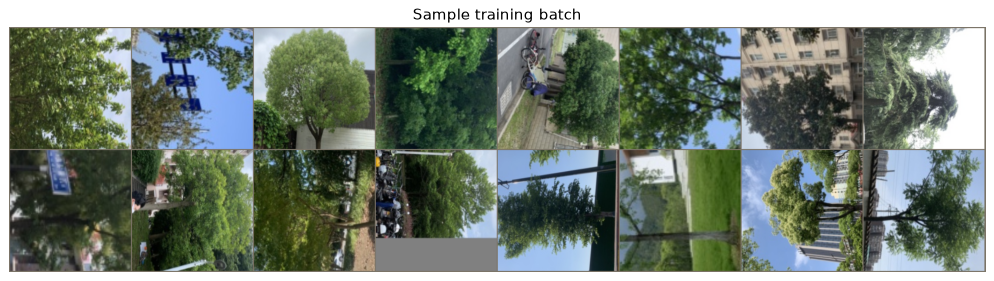

Labels: ['Flowering cherry', 'Triadica sebifera', 'Cinnamomum camphora (Linn) Presl', 'Triadica sebifera', 'Cinnamomum camphora (Linn) Presl', 'Koelreuteria paniculata', 'Magnolia grandiflora L', 'Cedrus deodara', 'Styphnolobium japonicum', 'Elaeocarpus decipiens', 'Acer palmatum', 'Michelia chapensis', 'Zelkova serrata', 'Ginkgo biloba', 'Cinnamomum camphora (Linn) Presl', 'Styphnolobium japonicum']


In [23]:
# Quick sanity check: visualize a batch of training images (after augmentation)
show_batch(loaders["train"])

## 7. Training Round 1 — Baseline

**Training settings**
- Both models use the same settings for a fair comparison
- Optimizer: Adam
- Learning rate: `1e-4`
- Weight decay: `1e-4`
- StepLR reduces the learning rate by 10 times every 7 epochs
- Training: 15 epochs, batch size 32
- Save the model with the best validation accuracy


# start a new training for ResNet18

## this is for Radeon grafhic card


In [ ]:
torch.backends.cudnn.enabled = False

In [24]:
EPOCHS = 15

model18 = make_model("resnet18")
model18, hist18 = train_epochs(model18, loaders["train"], loaders["val"],
                               epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model18.state_dict(), os.path.join(SAVE_DIR, "resnet18_round1.pth"))

plot_curves(hist18, "ResNet18")

RuntimeError: miopenStatusUnknownError

# start a new training for ResNet50

In [ ]:
model50 = make_model("resnet50")
model50, hist50 = train_epochs(model50, loaders["train"], loaders["val"],
                               epochs=EPOCHS, lr=1e-4, wd=1e-4, step_size=7, device=device)
torch.save(model50.state_dict(), os.path.join(SAVE_DIR, "resnet50_round1.pth")) 

plot_curves(hist50, "ResNet50")

Epoch  1 | train=1.9900 acc=0.4456 | val=0.9488 acc=0.7198  *best*
Epoch  2 | train=1.0125 acc=0.7082 | val=0.7440 acc=0.7725  *best*
Epoch  3 | train=0.7223 acc=0.7894 | val=0.4135 acc=0.8793  *best*
Epoch  4 | train=0.6425 acc=0.8096 | val=0.5068 acc=0.8544
Epoch  5 | train=0.5461 acc=0.8397 | val=0.3921 acc=0.8821  *best*
Epoch  6 | train=0.5037 acc=0.8528 | val=0.4336 acc=0.8669
Epoch  7 | train=0.4502 acc=0.8641 | val=0.5668 acc=0.8405
Epoch  8 | train=0.3412 acc=0.9030 | val=0.2907 acc=0.9071  *best*
Epoch  9 | train=0.2667 acc=0.9289 | val=0.2473 acc=0.9154  *best*
Epoch 10 | train=0.2608 acc=0.9265 | val=0.2727 acc=0.9112
Epoch 11 | train=0.2396 acc=0.9328 | val=0.2380 acc=0.9154
Epoch 12 | train=0.2125 acc=0.9432 | val=0.2414 acc=0.9168  *best*
Epoch 13 | train=0.2254 acc=0.9352 | val=0.1806 acc=0.9404  *best*
Epoch 14 | train=0.2199 acc=0.9366 | val=0.2137 acc=0.9320
Epoch 15 | train=0.2054 acc=0.9450 | val=0.2213 acc=0.9293
Training time: 12.8 min | best val acc: 0.9404


**Training observations:** _(fill in after running — e.g. how fast validation accuracy stopped improving,
how big the gap between train and val accuracy is (overfitting?), which model was better on validation, training times)_

# Load Trained Models

- Load saved ResNet18 and ResNet50 weights
- Use trained models without repeating training
- Prepare both models for final testing

In [26]:
# Load ResNet18
model18 = make_model("resnet18")
model18.load_state_dict(torch.load(
    os.path.join(SAVE_DIR, "resnet18_round1.pth"),
    map_location=device,
    weights_only=True
))
model18.eval()

# Load ResNet50
model50 = make_model("resnet50")
model50.load_state_dict(torch.load(
    os.path.join(SAVE_DIR, "resnet50_round1.pth"),
    map_location=device,
    weights_only=True
))
model50.eval()

print("Both models loaded successfully")

Both models loaded successfully


## 8. Testing on the test set
The test set (15 %) was not used during training or model selection.
Precision, recall and F1 are **macro averages** (computed per species, then averaged).

In [75]:
test_model(model18, "ResNet18", loaders["test"])
test_model(model50, "ResNet50", loaders["test"])

ResNet18     | accuracy 0.8835 | precision 0.9001 | recall 0.8954 | F1 0.8914
ResNet50     | accuracy 0.9320 | precision 0.9390 | recall 0.9381 | F1 0.9370


Per-species precision, recall and F1:

In [56]:
for name in ["ResNet18", "ResNet50"]:
    print("=" * 25, name, "=" * 25)
    print(classification_report(results[name]["y_true"], results[name]["y_pred"],
                                labels=range(num_classes), target_names=class_names, digits=3, zero_division=0))

========================= ResNet18 =========================
                                   precision    recall  f1-score   support

                    Acer palmatum      0.000     0.000     0.000        30
                   Cedrus deodara      0.000     0.000     0.000        24
                  Celtis sinensis      0.000     0.000     0.000        35
 Cinnamomum camphora (Linn) Presl      0.000     0.000     0.000        44
            Elaeocarpus decipiens      0.000     0.000     0.000        32
                 Flowering cherry      0.000     0.000     0.000        20
                    Ginkgo biloba      0.000     0.000     0.000        43
          Koelreuteria paniculata      0.000     0.000     0.000        42
             Lagerstroemia indica      0.000     0.000     0.000        12
            Liquidambar formosana      0.000     0.000     0.000        32
            Liriodendron chinense      0.000     0.000     0.000        34
           Magnolia grandiflora L     

### Confusion matrices
Rows = true species, columns = predicted species. Everything outside the diagonal is an error.

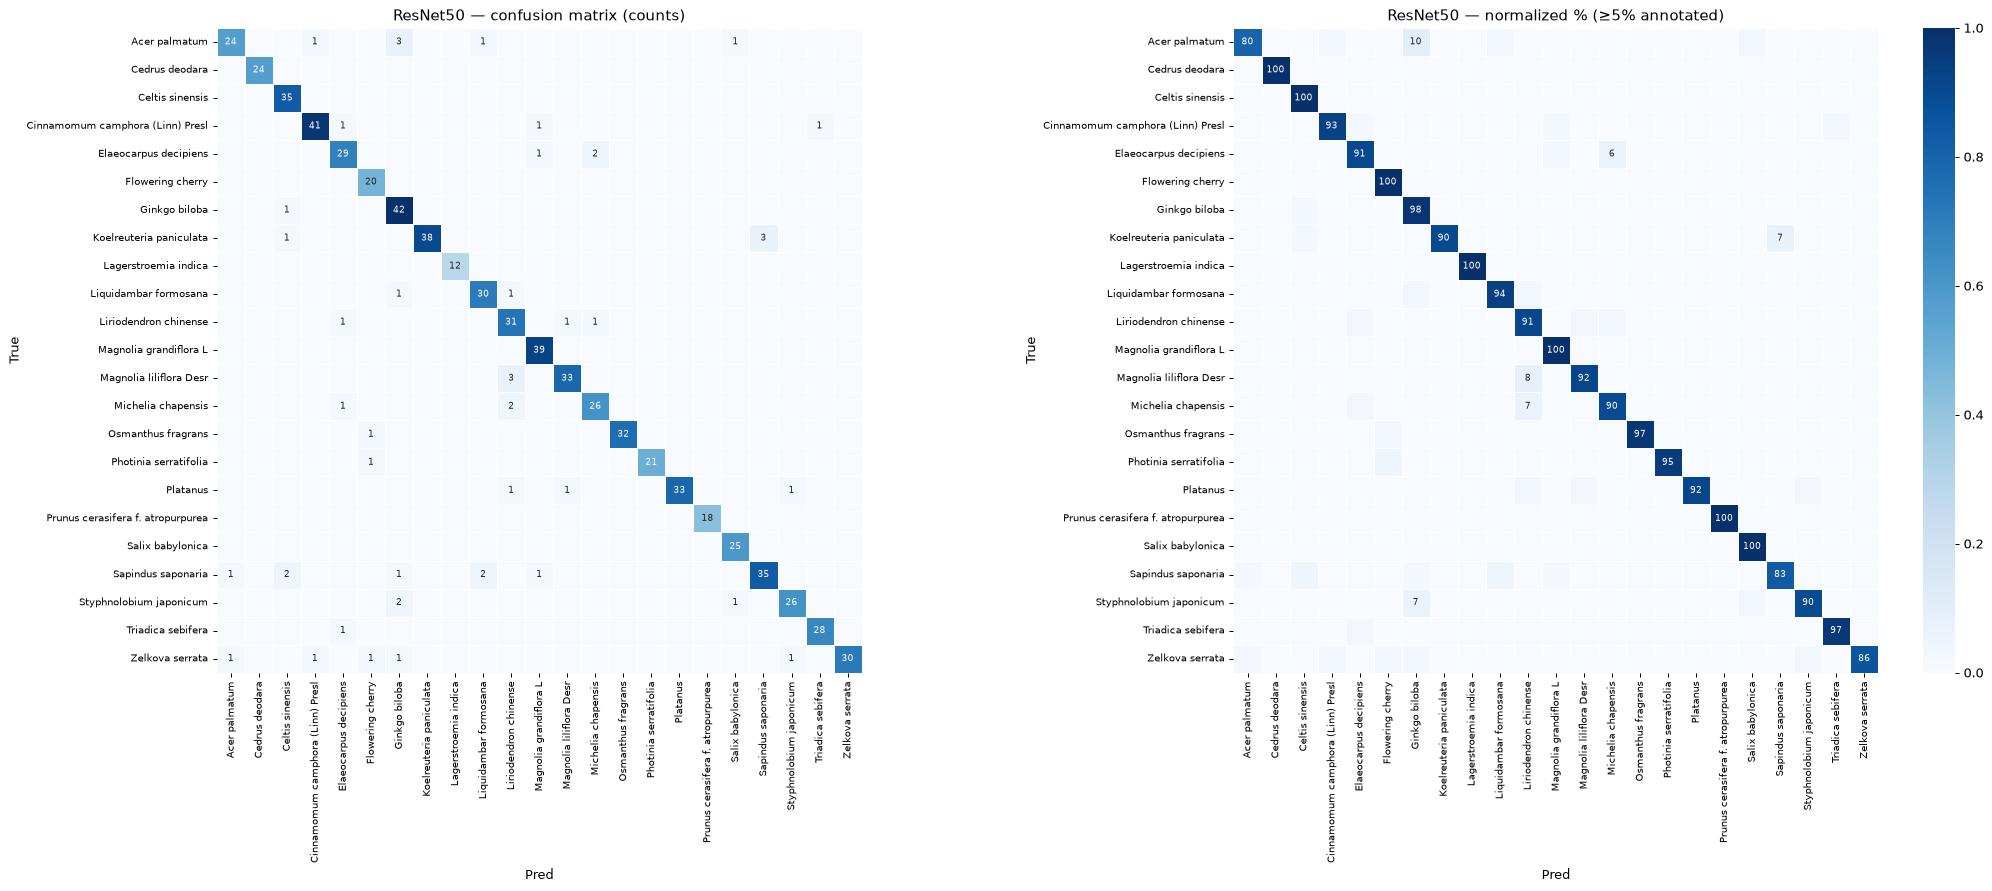

In [ ]:
show_confusion_matrices("ResNet18")
show_confusion_matrices("ResNet50")

# Highlight classification errorst
show_confusion_matrices("ResNet50", hide_diag_on_norm=True)

## 9. N-best (top-n) results
A prediction is counted correct if the true species is among the **n most probable** species.
n = 1 is normal accuracy; when n grows, both models go towards 100 %.

**Task:** find the value of n beyond which the n-best results separate (or stop separating) the two models.

The test set has ~700 images, so one image ≈ 0.14 %-points. We treat a difference smaller than
**1 %-point** (~7 images) as noise → the models are "not separated" at that n.

In [60]:
MAX_N = 10
ns = list(range(1, MAX_N + 1))

nbest = {name: [top_n_accuracy(results[name]["probs"], results[name]["y_true"], n) for n in ns]
         for name in ["ResNet18", "ResNet50"]}

nbest_df = pd.DataFrame(nbest, index=pd.Index(ns, name="n")) * 100
nbest_df["difference (50 - 18)"] = nbest_df["ResNet50"] - nbest_df["ResNet18"]
nbest_df.round(2)

,ResNet18,ResNet50,difference (50 - 18)
n,,,
1,5.83,93.20,87.38
2,8.88,97.09,88.21
3,12.34,98.06,85.71
4,16.50,98.61,82.11
5,20.39,98.89,78.50
6,24.83,99.17,74.34
7,29.13,99.45,70.32
8,32.87,99.45,66.57
9,37.17,99.58,62.41


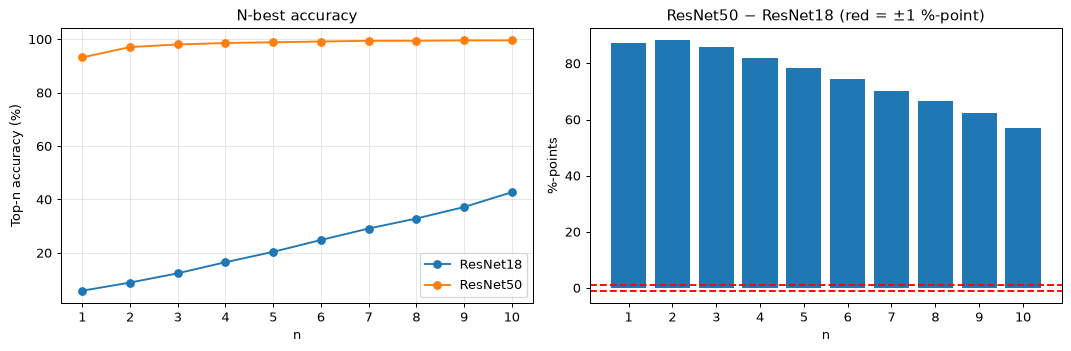

n values where the models differ by at least 1 %-point: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [61]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name in ["ResNet18", "ResNet50"]:
    ax1.plot(ns, nbest_df[name], marker="o", label=name)
ax1.set_xlabel("n"); ax1.set_ylabel("Top-n accuracy (%)"); ax1.set_title("N-best accuracy")
ax1.set_xticks(ns); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.bar(ns, nbest_df["difference (50 - 18)"])
ax2.axhline(1, color="red", ls="--"); ax2.axhline(-1, color="red", ls="--")
ax2.set_xlabel("n"); ax2.set_ylabel("%-points"); ax2.set_title("ResNet50 − ResNet18 (red = ±1 %-point)")
ax2.set_xticks(ns)
plt.tight_layout(); plt.show()

separated = [n for n in ns if abs(nbest_df.loc[n, "difference (50 - 18)"]) >= 1.0]
print("n values where the models differ by at least 1 %-point:", separated)

**N-best finding:** _(fill in from the table — e.g. "At n = 1 ResNet50 is X %-points better. The difference stays
over 1 %-point up to n = ?, after that both models almost always have the right species in their top-n,
so n-best does not separate them anymore." It is also possible that no clear n exists — then say so.)_

## 10. Error analysis
Which species get mixed up, and what do the wrong images look like?
TIP (from the lecture): look for **systematic** errors — they show dataset challenges or model weaknesses.

In [62]:
most_confused("ResNet18")
most_confused("ResNet50")

--- ResNet18: most common errors (true → predicted) ---
 32   Cinnamomum camphora (Linn) Presl  →  Salix babylonica
 27   Michelia chapensis  →  Magnolia liliflora Desr
 26   Zelkova serrata  →  Salix babylonica
 25   Koelreuteria paniculata  →  Salix babylonica
 24   Magnolia grandiflora L  →  Magnolia liliflora Desr
 22   Platanus  →  Salix babylonica
 22   Celtis sinensis  →  Salix babylonica
 21   Triadica sebifera  →  Salix babylonica
 21   Styphnolobium japonicum  →  Salix babylonica
 21   Sapindus saponaria  →  Salix babylonica
--- ResNet50: most common errors (true → predicted) ---
  3   Magnolia liliflora Desr  →  Liriodendron chinense
  3   Koelreuteria paniculata  →  Sapindus saponaria
  3   Acer palmatum  →  Ginkgo biloba
  2   Styphnolobium japonicum  →  Ginkgo biloba
  2   Sapindus saponaria  →  Liquidambar formosana
  2   Sapindus saponaria  →  Celtis sinensis
  2   Michelia chapensis  →  Liriodendron chinense
  2   Elaeocarpus decipiens  →  Michelia chapensis
  1   Zelk

ResNet50: 49 wrong out of 721 test images


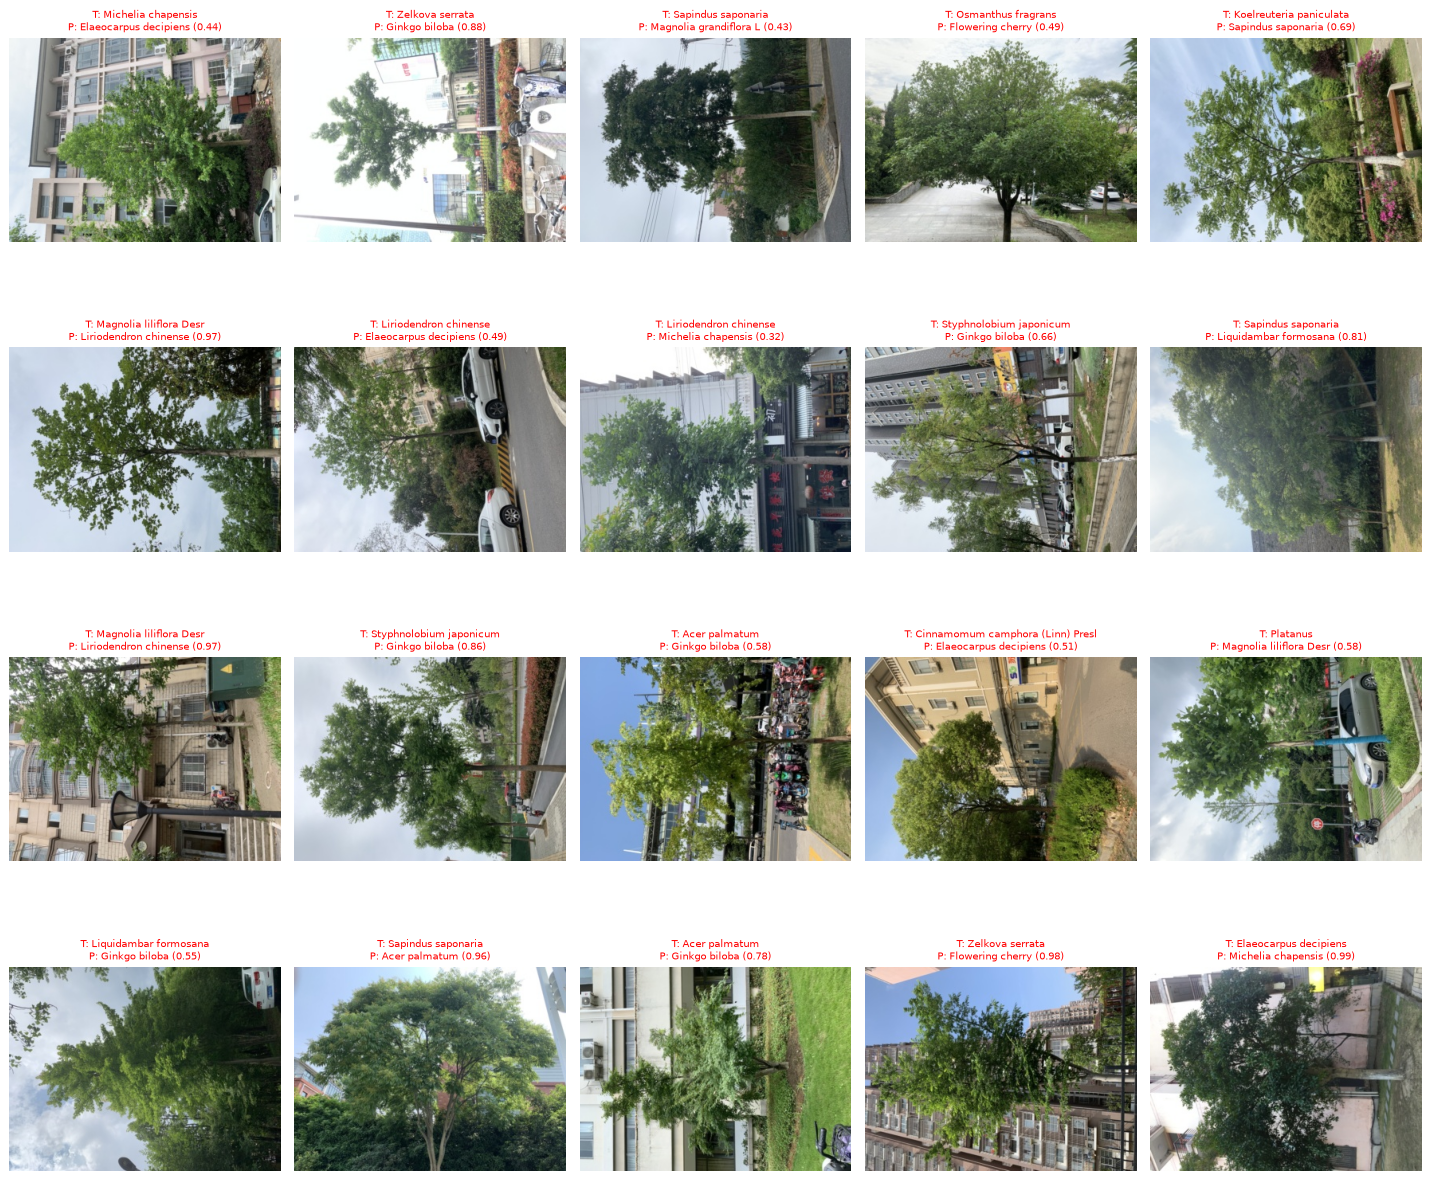

In [63]:
show_misclassified("ResNet50", k=20)

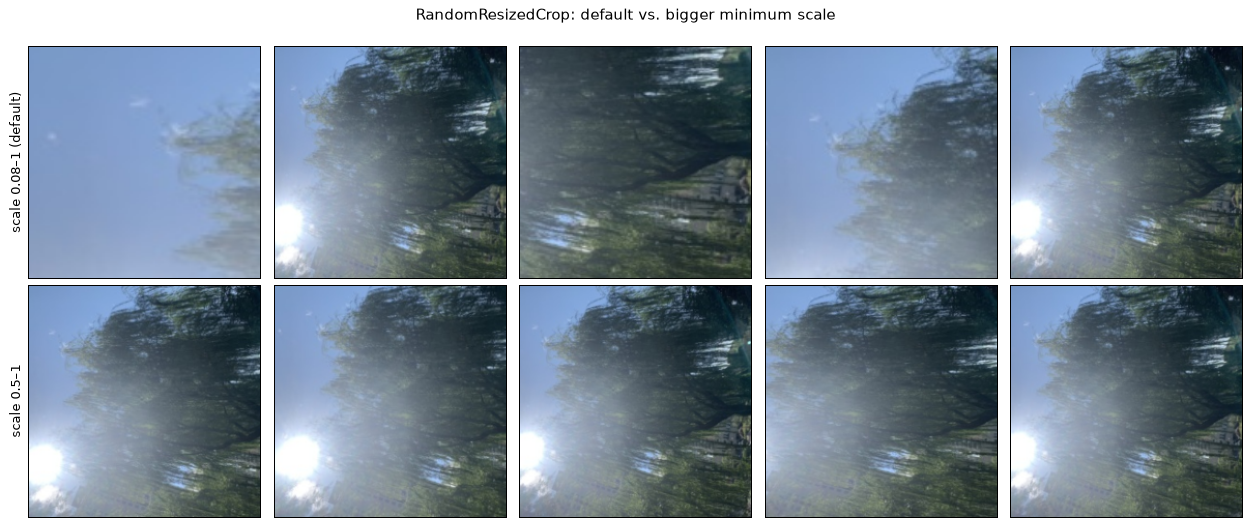

In [64]:
# How much of the tree does RandomResizedCrop keep? Default scale = 8%-100% of the image area.
img = Image.open(train_p[1]).convert("RGB")
fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for j in range(5):
    axs[0, j].imshow(T.RandomResizedCrop(224)(img))
    axs[1, j].imshow(T.RandomResizedCrop(224, scale=(0.5, 1.0))(img))
    axs[0, j].set_xticks([]); axs[0, j].set_yticks([]); axs[1, j].set_xticks([]); axs[1, j].set_yticks([])
axs[0, 0].set_ylabel("scale 0.08–1 (default)"); axs[1, 0].set_ylabel("scale 0.5–1")
plt.suptitle("RandomResizedCrop: default vs. bigger minimum scale"); plt.tight_layout(); plt.show()

**What we noticed** _(edit after looking at your own results)_
- Some species look very similar (same leaf/crown shape) and are confused by **both** models.
- Many errors are **winter** photos (no leaves, only branches) or photos with strong light/shadows.
- The tree is often **small** in the photo, or there are several trees, buildings, cars, people.
  The default `RandomResizedCrop` can cut out a piece with only sky or road, so the model learns from wrong crops.
- Wrong predictions often have low confidence → the right answer is usually in the top-2/top-3 (see n-best).

**Changes for round 2**
1. `RandomResizedCrop(224, scale=(0.5, 1.0))` → crops always contain a big part of the tree
2. `ColorJitter` → robustness to light and season differences
3. small `RandomRotation(10)` → photos are not always straight
4. **label smoothing 0.1** → less over-confident between similar species
5. **20 epochs** (lr step every 8) because the stronger augmentation makes training harder

## 11. Training round 2 — improved models

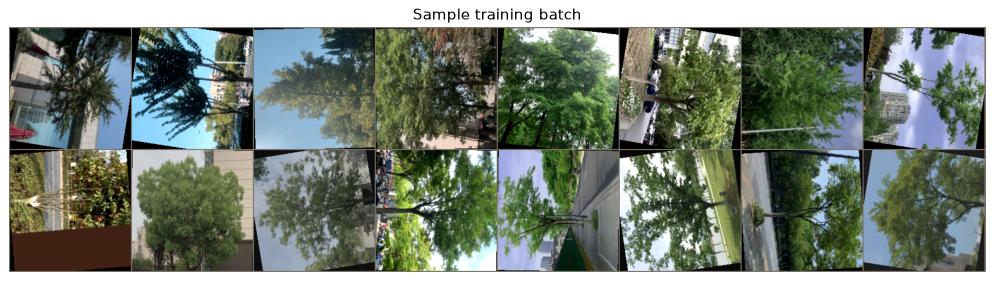

Labels: ['Cedrus deodara', 'Lagerstroemia indica', 'Liquidambar formosana', 'Koelreuteria paniculata', 'Liquidambar formosana', 'Magnolia liliflora Desr', 'Ginkgo biloba', 'Sapindus saponaria', 'Photinia serratifolia', 'Cinnamomum camphora (Linn) Presl', 'Koelreuteria paniculata', 'Koelreuteria paniculata', 'Koelreuteria paniculata', 'Flowering cherry', 'Celtis sinensis', 'Celtis sinensis']


In [65]:
train_tfms_v2 = T.Compose([
    T.RandomResizedCrop(224, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

loaders_v2 = make_loaders(train_tfms_v2)   # val/test unchanged -> results are comparable
EPOCHS_V2 = 20

show_batch(loaders_v2["train"])

### 11.1 ResNet18 v2

Epoch  1 | train=2.3521 acc=0.3882 | val=1.6387 acc=0.6130  *best*
Epoch  2 | train=1.4658 acc=0.7064 | val=1.2549 acc=0.7781  *best*
Epoch  3 | train=1.2192 acc=0.8010 | val=1.2839 acc=0.7698
Epoch  4 | train=1.0695 acc=0.8608 | val=1.0942 acc=0.8280  *best*
Epoch  5 | train=1.0001 acc=0.8894 | val=1.1312 acc=0.8197
Epoch  6 | train=0.9246 acc=0.9197 | val=1.0719 acc=0.8516  *best*
Epoch  7 | train=0.8931 acc=0.9346 | val=1.0761 acc=0.8530  *best*
Epoch  8 | train=0.8756 acc=0.9349 | val=1.0467 acc=0.8613  *best*
Epoch  9 | train=0.8154 acc=0.9616 | val=0.9876 acc=0.8807  *best*
Epoch 10 | train=0.7920 acc=0.9685 | val=0.9970 acc=0.8821  *best*
Epoch 11 | train=0.7826 acc=0.9777 | val=1.0013 acc=0.8890  *best*
Epoch 12 | train=0.7749 acc=0.9798 | val=0.9868 acc=0.8918  *best*
Epoch 13 | train=0.7806 acc=0.9795 | val=0.9624 acc=0.8988  *best*
Epoch 14 | train=0.7770 acc=0.9753 | val=1.0029 acc=0.8877
Epoch 15 | train=0.7684 acc=0.9810 | val=0.9683 acc=0.8988
Epoch 16 | train=0.7596 acc

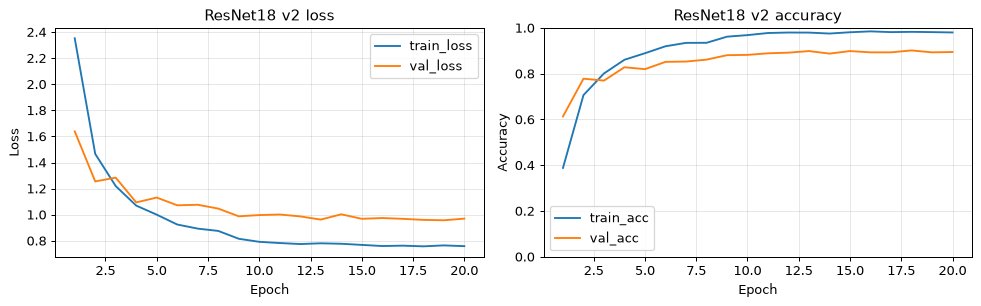

In [66]:
model18_v2 = make_model("resnet18")
model18_v2, hist18_v2 = train_epochs(model18_v2, loaders_v2["train"], loaders_v2["val"], epochs=EPOCHS_V2,
                                     lr=1e-4, wd=1e-4, step_size=8, label_smoothing=0.1, device=device)
torch.save(model18_v2.state_dict(), os.path.join(SAVE_DIR, "resnet18_round2.pth"))
plot_curves(hist18_v2, "ResNet18 v2")

### 11.2 ResNet50 v2

Epoch  1 | train=2.1955 acc=0.4536 | val=1.5215 acc=0.6644  *best*
Epoch  2 | train=1.3201 acc=0.7617 | val=1.2129 acc=0.7878  *best*
Epoch  3 | train=1.1069 acc=0.8385 | val=1.0359 acc=0.8710  *best*
Epoch  4 | train=0.9971 acc=0.8798 | val=1.0392 acc=0.8599
Epoch  5 | train=0.9390 acc=0.9030 | val=1.0567 acc=0.8530
Epoch  6 | train=0.8888 acc=0.9262 | val=1.0338 acc=0.8544
Epoch  7 | train=0.8694 acc=0.9337 | val=0.9280 acc=0.9057  *best*
Epoch  8 | train=0.8224 acc=0.9545 | val=0.9140 acc=0.9071  *best*
Epoch  9 | train=0.7675 acc=0.9706 | val=0.8659 acc=0.9307  *best*
Epoch 10 | train=0.7391 acc=0.9830 | val=0.8679 acc=0.9307
Epoch 11 | train=0.7394 acc=0.9819 | val=0.8492 acc=0.9348  *best*
Epoch 12 | train=0.7245 acc=0.9863 | val=0.8433 acc=0.9404  *best*
Epoch 13 | train=0.7214 acc=0.9869 | val=0.8597 acc=0.9265
Epoch 14 | train=0.7219 acc=0.9860 | val=0.8607 acc=0.9251
Epoch 15 | train=0.7160 acc=0.9893 | val=0.8617 acc=0.9307
Epoch 16 | train=0.7094 acc=0.9908 | val=0.8539 acc

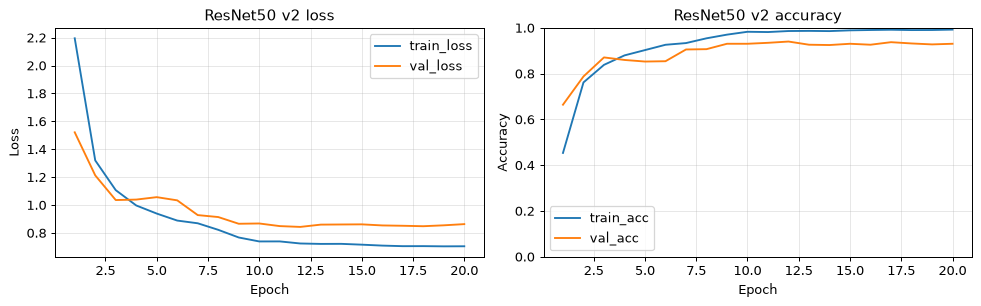

In [69]:
model50_v2 = make_model("resnet50")
model50_v2, hist50_v2 = train_epochs(model50_v2, loaders_v2["train"], loaders_v2["val"], epochs=EPOCHS_V2,
                                     lr=1e-4, wd=1e-4, step_size=8, label_smoothing=0.1, device=device)
torch.save(model50_v2.state_dict(), os.path.join(SAVE_DIR, "resnet50_round2.pth"))
plot_curves(hist50_v2, "ResNet50 v2")

### 11.3 Test results of the improved models

In [70]:
test_model(model18_v2, "ResNet18 v2", loaders_v2["test"])
test_model(model50_v2, "ResNet50 v2", loaders_v2["test"])

ResNet18 v2  | accuracy 0.8890 | precision 0.8971 | recall 0.8996 | F1 0.8914
ResNet50 v2  | accuracy 0.9279 | precision 0.9348 | recall 0.9337 | F1 0.9318


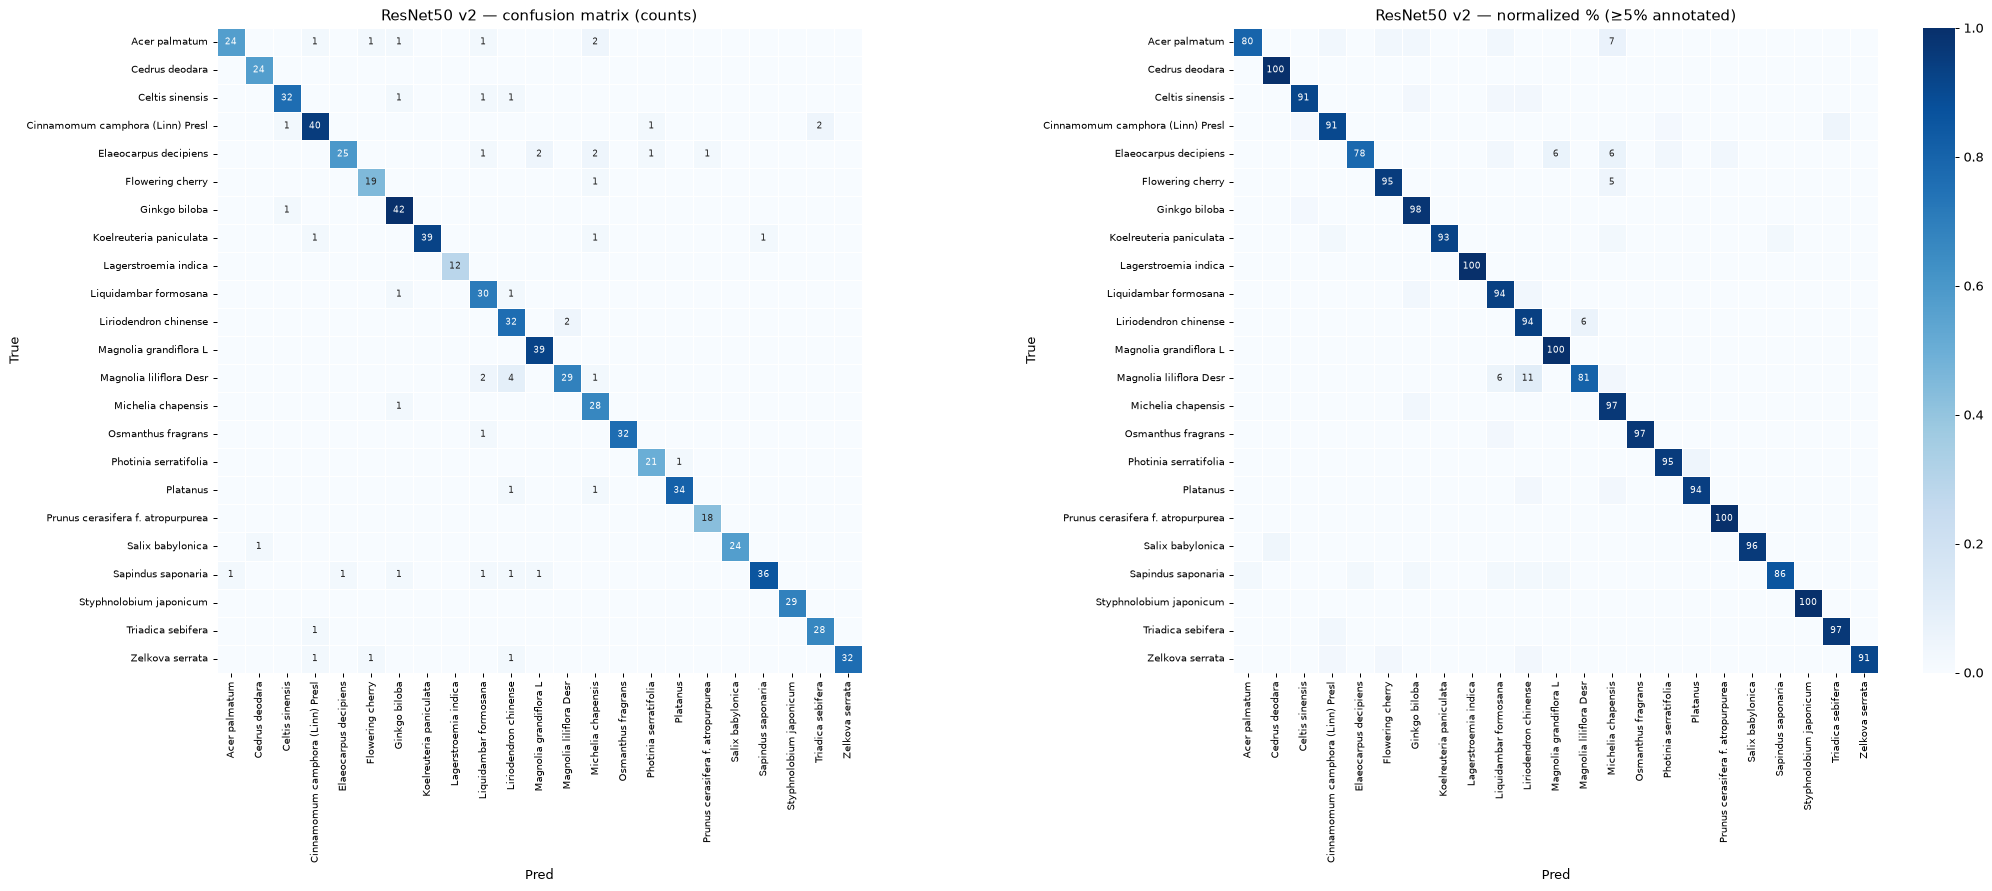

--- ResNet50 v2: most common errors (true → predicted) ---
  4   Magnolia liliflora Desr  →  Liriodendron chinense
  2   Magnolia liliflora Desr  →  Liquidambar formosana
  2   Liriodendron chinense  →  Magnolia liliflora Desr
  2   Elaeocarpus decipiens  →  Michelia chapensis
  2   Elaeocarpus decipiens  →  Magnolia grandiflora L
  2   Cinnamomum camphora (Linn) Presl  →  Triadica sebifera
  2   Acer palmatum  →  Michelia chapensis
  1   Zelkova serrata  →  Liriodendron chinense
  1   Zelkova serrata  →  Flowering cherry
  1   Zelkova serrata  →  Cinnamomum camphora (Linn) Presl


In [71]:
show_confusion_matrices("ResNet50 v2")
most_confused("ResNet50 v2")

## 12. Final comparison

In [76]:
summary = pd.DataFrame({name: {k: r[k] for k in ["accuracy", "precision", "recall", "f1"]}
                        for name, r in results.items()}).T
summary.round(4)

,accuracy,precision,recall,f1
ResNet18,0.8835,0.9001,0.8954,0.8914
ResNet50,0.9320,0.9390,0.9381,0.9370
ResNet18 v2,0.8890,0.8971,0.8996,0.8914
ResNet50 v2,0.9279,0.9348,0.9337,0.9318


### Model Comparison

**Key findings**
- ResNet50 achieved the highest test accuracy at **93.20%**
- ResNet18 improved slightly in round 2 from 88.35% to 88.90%
- ResNet50 decreased slightly in round 2 from 93.20% to 92.79%
- The second training round did not significantly improve performance
- ResNet50 from round 1 was selected as the best model

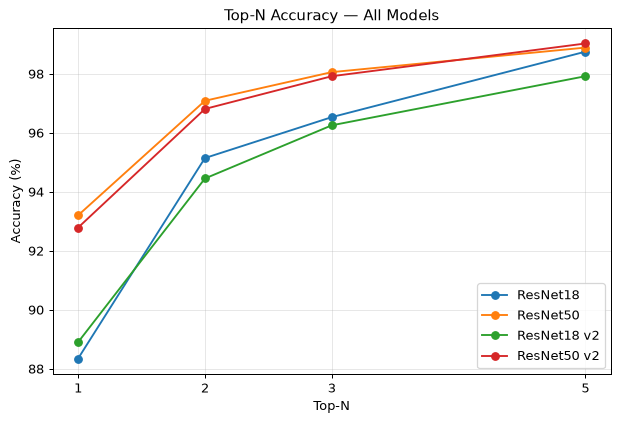

,ResNet18,ResNet50,ResNet18 v2,ResNet50 v2
n,,,,
1,88.35,93.20,88.90,92.79
2,95.15,97.09,94.45,96.81
3,96.53,98.06,96.26,97.92
5,98.75,98.89,97.92,99.03


In [81]:
# Top-N accuracy for all models
ns = [1, 2, 3, 5]
all_names = list(results.keys())

nbest_all = pd.DataFrame({
    name: [
        top_n_accuracy(results[name]["probs"], results[name]["y_true"], n) * 100
        for n in ns
    ]
    for name in all_names
}, index=pd.Index(ns, name="n"))

# Plot results
plt.figure(figsize=(8, 5))

for name in all_names:
    plt.plot(ns, nbest_all[name], marker="o", label=name)

plt.xlabel("Top-N")
plt.ylabel("Accuracy (%)")
plt.title("Top-N Accuracy — All Models")
plt.xticks(ns)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Display comparison table
nbest_all.round(2)

## Conclusions
_(fill in with your own numbers)_


**Round 1**
- ResNet18 achieved 88.35% test accuracy
- ResNet50 achieved 93.20% test accuracy
- ResNet50 performed better by 4.85 percentage points

**Top-N Accuracy**
- ResNet50 achieved 97.09% Top-2 accuracy
- ResNet50 achieved 98.06% Top-3 accuracy
- ResNet50 achieved 98.89% Top-5 accuracy

**Round 2**
- ResNet18 improved slightly from 88.35% to 88.90%
- ResNet50 decreased slightly from 93.20% to 92.79%
- The changes in round 2 did not improve the best model

**Final Result**
- ResNet50 from round 1 was the best model
- Best test accuracy: 93.20%
- Best F1-score: 93.70%

**Possible Improvements**
- Try EfficientNet
- Use larger image sizes
- Improve tree cropping
- Test different augmentation settings

Trained models (not included in the zip): _(Google Drive link here)_